# Amazon Best-Selling Books Analysis Using Python and Pandas
**Project Level:** Exploratory Data Analysis & Business Intelligence  
**Tech Stack:** Python 3, Pandas, NumPy, Matplotlib, Seaborn, Pathlib  

---

### Project Overview
This project provides a complete exploratory data analysis (EDA) of a 1,000-record synthetic Amazon best-selling book catalog.

> **Dataset Disclaimer:** This dataset contains simulated synthetic data for analytical and educational demonstration. It does not represent actual proprietary Amazon e-commerce sales or internal metrics.

#### Objectives:
1. **Data Loading:** Ingest raw CSV data, evaluate dimensions, columns, and initial records.
2. **Data Cleaning:** Handle missing values, eliminate duplicate rows, validate domain boundaries.
3. **Exploratory Data Analysis (EDA):** Identify top-selling titles, compute catalog benchmarks (averages, distributions), analyze genre and format performance, and investigate review-to-sales correlations.
4. **Data Visualization:** Produce publication-ready visualizations.
5. **Business Insights:** Generate actionable, evidence-based insights backed by computed data.


In [1]:
# Step 0: Imports and Dynamic Project Path Setup
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Resolve Project Root dynamically (handles both running from project root or inside notebooks/)
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR if (NOTEBOOK_DIR / "data").exists() else NOTEBOOK_DIR.parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "amazon_bestselling_books_dummy.csv"
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_books_data.csv"
CHARTS_DIR = PROJECT_ROOT / "outputs" / "charts"
REPORTS_DIR = PROJECT_ROOT / "outputs" / "reports"

# Ensure output directories exist
PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Styling configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 16
})

print(f"Project Root: {PROJECT_ROOT}")
print(f"Raw Data Path: {RAW_DATA_PATH} (Exists: {RAW_DATA_PATH.exists()})")


Project Root: D:\React Native\analye selling
Raw Data Path: D:\React Native\analye selling\data\raw\amazon_bestselling_books_dummy.csv (Exists: True)


---
## 1. Data Loading
We load the original dataset from `data/raw/amazon_bestselling_books_dummy.csv` and inspect its initial shape, columns, and data types.


In [2]:
# 1.1 Load the raw dataset
df_raw = pd.read_csv(RAW_DATA_PATH)

print(f"Dataset Dimensions: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns\n")
print("Columns in Dataset:")
print(list(df_raw.columns))


Dataset Dimensions: 1000 rows, 10 columns

Columns in Dataset:
['book_id', 'title', 'author', 'genre', 'format', 'price_usd', 'rating', 'review_count', 'estimated_monthly_units_sold', 'publication_year']


In [3]:
# 1.2 Inspect the first 5 records
df_raw.head()


,book_id,title,author,genre,format,price_usd,rating,review_count,estimated_monthly_units_sold,publication_year
0,B01001,The Modern Equation of Brown,Brené Brown,Self-Help,Paperback,18.94,4.1,1577,2642,2017
1,B01002,The Hidden Code of Orwell,George Orwell,Fiction,Hardcover,36.47,4.2,1014,1393,2016
2,B01003,The Brave Habits of Sanderson,Brandon Sanderson,Sci-Fi & Fantasy,Paperback,15.99,4.3,1509,2985,2017
3,B01004,The Infinite Code of Ng,Andrew Ng,Technology,Paperback,12.55,4.2,1311,2804,2018
4,B01005,The Essential Strategy of Marquez,Gabriel Garcia Marquez,Fiction,Kindle,7.68,4.6,833,2551,2015


In [4]:
# 1.3 Data types and memory usage
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   book_id                       1000 non-null   str    
 1   title                         1000 non-null   str    
 2   author                        1000 non-null   str    
 3   genre                         1000 non-null   str    
 4   format                        1000 non-null   str    
 5   price_usd                     997 non-null    float64
 6   rating                        996 non-null    float64
 7   review_count                  1000 non-null   int64  
 8   estimated_monthly_units_sold  1000 non-null   int64  
 9   publication_year              1000 non-null   int64  
dtypes: float64(2), int64(3), str(5)
memory usage: 78.3 KB


In [5]:
# 1.4 Descriptive statistical summary of numerical features
df_raw.describe()


,price_usd,rating,review_count,estimated_monthly_units_sold,publication_year
count,997.000000,996.00000,1000.000000,1000.000000,1000.000000
mean,15.262056,4.39749,3205.382000,3972.011000,2017.933000
std,8.228966,0.33241,4865.392294,2730.517932,3.536809
min,3.050000,3.30000,50.000000,386.000000,2010.000000
25%,9.260000,4.20000,801.750000,2027.000000,2016.000000
50%,13.540000,4.40000,1693.000000,3162.000000,2019.000000
75%,20.480000,4.60000,3632.000000,5067.750000,2021.000000
max,39.920000,5.00000,53953.000000,15000.000000,2024.000000


---
## 2. Data Cleaning & Validation
Data hygiene steps performed:
1. **Duplicate Detection & Removal:** Find duplicate `book_id` records.
2. **Missing Value Imputation:** Impute missing `price_usd` using format-specific medians and missing `rating` using genre-specific medians.
3. **Range Validation:** Ensure prices > 0, ratings ∈ [1.0, 5.0], and sales/reviews ≥ 0.
4. **Data Export:** Export cleaned dataset to `data/processed/cleaned_books_data.csv`.


In [6]:
# 2.1 Check for duplicate records
duplicates_count = df_raw.duplicated(subset=['book_id']).sum()
print(f"Duplicate book_id records detected: {duplicates_count}")

# Drop duplicates, retaining first occurrence
df_clean = df_raw.drop_duplicates(subset=['book_id']).copy()
print(f"Records retained after deduplication: {len(df_clean)}")


Duplicate book_id records detected: 5
Records retained after deduplication: 995


In [7]:
# 2.2 Identify missing values per column
missing_vals = df_clean.isnull().sum()
print("Missing values:")
print(missing_vals[missing_vals > 0])


Missing values:
price_usd    3
rating       4
dtype: int64


In [8]:
# 2.3 Impute missing values with group medians
# Impute missing price using the median price of that specific format (Kindle vs Paperback vs Hardcover)
df_clean['price_usd'] = df_clean.groupby('format')['price_usd'].transform(
    lambda s: s.fillna(s.median())
)

# Impute missing rating using the median rating for that genre
df_clean['rating'] = df_clean.groupby('genre')['rating'].transform(
    lambda s: s.fillna(round(s.median(), 1))
)

print("Remaining null values after imputation:", df_clean.isnull().sum().sum())


Remaining null values after imputation: 0


In [9]:
# 2.4 Validate numeric domain boundaries
assert (df_clean['price_usd'] > 0).all(), "Invalid non-positive price found"
assert (df_clean['rating'].between(1.0, 5.0)).all(), "Invalid rating outside 1.0-5.0"
assert (df_clean['estimated_monthly_units_sold'] >= 0).all(), "Negative sales found"
assert (df_clean['review_count'] >= 0).all(), "Negative reviews found"

# Reset index and export to processed data directory
df_clean.reset_index(drop=True, inplace=True)
df_clean.to_csv(PROCESSED_DATA_PATH, index=False)
print(f"Cleaned dataset successfully saved to: {PROCESSED_DATA_PATH}")


Cleaned dataset successfully saved to: D:\React Native\analye selling\data\processed\cleaned_books_data.csv


---
## 3. Exploratory Data Analysis (EDA)
Comprehensive exploration of:
- Top 10 books by estimated monthly sales volume
- Average book price & average rating
- Genre performance and market share
- Author performance analysis
- Format comparison (Kindle, Paperback, Hardcover)
- Review count, rating, and sales correlation matrix


In [10]:
# 3.1 Top 10 Books by Estimated Monthly Units Sold
top_10_books = df_clean.nlargest(10, 'estimated_monthly_units_sold')[
    ['book_id', 'title', 'author', 'genre', 'format', 'price_usd', 'rating', 'review_count', 'estimated_monthly_units_sold']
]

# Save report
top_10_books.to_csv(REPORTS_DIR / "top_10_books.csv", index=False)
top_10_books[['title', 'author', 'genre', 'format', 'price_usd', 'rating', 'estimated_monthly_units_sold']]


,title,author,genre,format,price_usd,rating,estimated_monthly_units_sold
82,The Essential Empire of Huberman,Andrew Huberman,Health & Wellness,Kindle,12.52,4.6,15000
211,The Deep Empire of Hoover,Colleen Hoover,Fiction,Paperback,15.32,4.2,15000
261,The Digital Art of Hazelwood,Ali Hazelwood,Romance,Kindle,7.71,4.9,15000
479,The Modern Mind of Noah,Trevor Noah,Biography & Memoir,Kindle,3.30,4.8,15000
541,The Brave Empire of Clear,James Clear,Self-Help,Kindle,7.64,4.0,15000
755,The Modern Empire of Weir,Andy Weir,Sci-Fi & Fantasy,Kindle,12.61,3.8,15000
788,The Brave Art of Carnegie,Dale Carnegie,Self-Help,Paperback,19.07,4.2,15000
809,The Courageous Mind of Orwell,George Orwell,Fiction,Kindle,11.19,4.4,15000
849,The Brave Empire of Haig,Matt Haig,Fiction,Kindle,13.49,4.6,15000
33,The Deep Shadows of Bryson,Bill Bryson,Non-Fiction,Kindle,3.61,5.0,14786


In [11]:
# 3.2 Overall Catalog Metrics
avg_price = df_clean['price_usd'].mean()
median_price = df_clean['price_usd'].median()
avg_rating = df_clean['rating'].mean()
total_sales = df_clean['estimated_monthly_units_sold'].sum()
avg_sales_per_title = df_clean['estimated_monthly_units_sold'].mean()

print(f"Catalog Key Metrics:")
print(f"• Average Book Price: ${avg_price:.2f}")
print(f"• Median Book Price:  ${median_price:.2f}")
print(f"• Average Rating:     {avg_rating:.2f} / 5.00")
print(f"• Total Catalog Monthly Estimated Sales: {total_sales:,} units")
print(f"• Average Monthly Units Sold per Title:   {avg_sales_per_title:.1f} units")


Catalog Key Metrics:
• Average Book Price: $15.27
• Median Book Price:  $13.54
• Average Rating:     4.40 / 5.00
• Total Catalog Monthly Estimated Sales: 3,958,547 units
• Average Monthly Units Sold per Title:   3978.4 units


In [12]:
# 3.3 Genre Performance Analysis
genre_analysis = df_clean.groupby('genre').agg(
    book_count=('book_id', 'count'),
    total_monthly_sales=('estimated_monthly_units_sold', 'sum'),
    avg_monthly_sales=('estimated_monthly_units_sold', 'mean'),
    avg_price_usd=('price_usd', 'mean'),
    avg_rating=('rating', 'mean'),
    avg_reviews=('review_count', 'mean')
).reset_index()

genre_analysis['sales_share_pct'] = (
    genre_analysis['total_monthly_sales'] / total_sales * 100
).round(2)

genre_analysis.sort_values(by='total_monthly_sales', ascending=False, inplace=True)
genre_analysis.to_csv(REPORTS_DIR / "genre_analysis.csv", index=False)
genre_analysis


,genre,book_count,total_monthly_sales,avg_monthly_sales,avg_price_usd,avg_rating,avg_reviews,sales_share_pct
2,Fiction,164,658347,4014.310976,15.575366,4.370732,3423.859756,16.63
5,Non-Fiction,158,629804,3986.101266,15.750316,4.381013,3274.316456,15.91
7,Sci-Fi & Fantasy,134,570673,4258.753731,16.162687,4.418657,3849.029851,14.42
8,Self-Help,127,496546,3909.811024,14.609843,4.405512,2935.102362,12.54
1,Business & Finance,118,481884,4083.762712,14.910424,4.411017,3330.550847,12.17
4,Mystery & Thriller,90,321150,3568.333333,14.343444,4.407778,2333.066667,8.11
0,Biography & Memoir,66,267823,4057.924242,15.646364,4.383333,3327.227273,6.77
3,Health & Wellness,51,216673,4248.490196,14.906667,4.496078,2968.176471,5.47
6,Romance,53,182787,3448.811321,15.548208,4.369811,2976.773585,4.62
9,Technology,34,132860,3907.647059,13.679118,4.347059,2972.147059,3.36


In [13]:
# 3.4 Author Performance Analysis
author_analysis = df_clean.groupby('author').agg(
    titles_published=('book_id', 'count'),
    total_sales=('estimated_monthly_units_sold', 'sum'),
    avg_sales_per_title=('estimated_monthly_units_sold', 'mean'),
    avg_rating=('rating', 'mean'),
    primary_genre=('genre', lambda g: g.mode()[0])
).reset_index().sort_values(by='total_sales', ascending=False)

author_analysis.to_csv(REPORTS_DIR / "author_analysis.csv", index=False)
print("Top 10 Authors by Total Estimated Sales:")
author_analysis.head(10)


Top 10 Authors by Total Estimated Sales:


,author,titles_published,total_sales,avg_sales_per_title,avg_rating,primary_genre
46,Rebecca Skloot,31,150377,4850.870968,4.380645,Non-Fiction
58,Yuval Noah Harari,30,126191,4206.366667,4.313333,Non-Fiction
35,Michael Lewis,28,122795,4385.535714,4.396429,Non-Fiction
17,Eric Ries,27,114995,4259.074074,4.433333,Business & Finance
45,Ray Dalio,24,110906,4621.083333,4.470833,Business & Finance
25,Isaac Asimov,21,110800,5276.190476,4.509524,Sci-Fi & Fantasy
39,Neil Gaiman,27,107973,3999.000000,4.507407,Sci-Fi & Fantasy
12,Colleen Hoover,22,106238,4829.000000,4.209091,Fiction
28,Jane Austen,28,104447,3730.250000,4.464286,Fiction
5,Andy Weir,23,103592,4504.000000,4.443478,Sci-Fi & Fantasy


In [14]:
# 3.5 Format Comparison (Kindle vs Paperback vs Hardcover)
format_comparison = df_clean.groupby('format').agg(
    titles_count=('book_id', 'count'),
    total_sales=('estimated_monthly_units_sold', 'sum'),
    avg_sales=('estimated_monthly_units_sold', 'mean'),
    avg_price=('price_usd', 'mean'),
    avg_rating=('rating', 'mean')
).reset_index()

format_comparison['sales_share_pct'] = (
    format_comparison['total_sales'] / total_sales * 100
).round(2)

format_comparison.to_csv(REPORTS_DIR / "format_analysis.csv", index=False)
format_comparison


,format,titles_count,total_sales,avg_sales,avg_price,avg_rating,sales_share_pct
0,Hardcover,154,447276,2904.389610,29.026883,4.414286,11.30
1,Kindle,469,2107969,4494.603412,9.016620,4.385928,53.25
2,Paperback,372,1403302,3772.317204,17.466694,4.405914,35.45


In [15]:
# 3.6 Numeric Correlation Matrix
numeric_cols = ['price_usd', 'rating', 'review_count', 'estimated_monthly_units_sold', 'publication_year']
correlation_matrix = df_clean[numeric_cols].corr()
correlation_matrix.round(3)


,price_usd,rating,review_count,estimated_monthly_units_sold,publication_year
price_usd,1.000,0.032,-0.016,-0.172,-0.046
rating,0.032,1.000,-0.004,0.098,-0.043
review_count,-0.016,-0.004,1.000,0.811,0.005
estimated_monthly_units_sold,-0.172,0.098,0.811,1.000,-0.008
publication_year,-0.046,-0.043,0.005,-0.008,1.000


---
## 4. Data Visualization
Charts generated and saved into `outputs/charts/`:
1. Top 10 Books Bar Chart
2. Total Monthly Sales by Genre
3. Distribution of Book Prices Across Formats
4. Customer Rating Distribution
5. Review Count vs Estimated Monthly Sales (Log-Log)


findfont: Failed to find font weight semibold for Arial, now using 700.


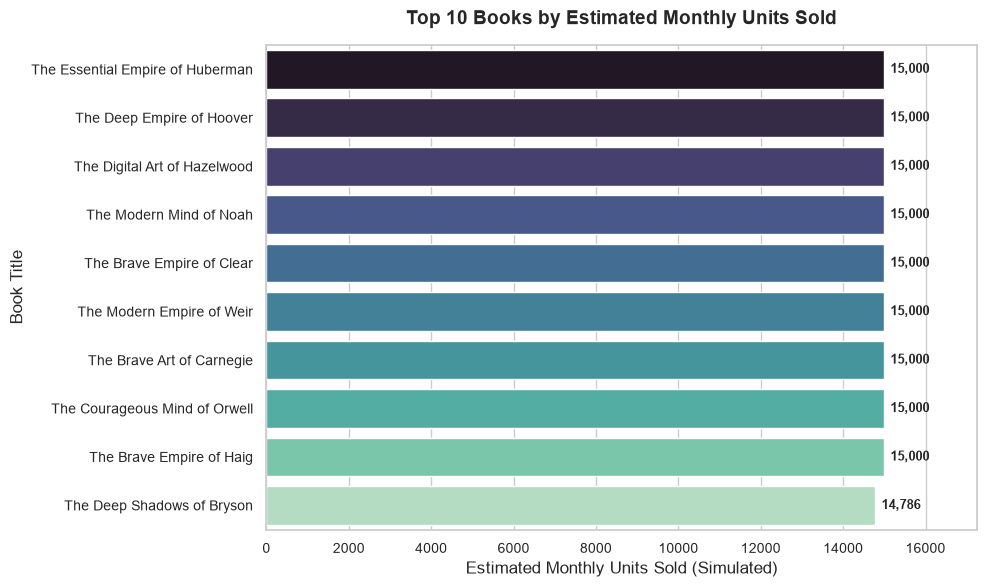

In [16]:
# Chart 1: Bar chart of Top 10 Books
plt.figure(figsize=(10, 6))
palette = sns.color_palette("mako", len(top_10_books))
ax = sns.barplot(
    data=top_10_books,
    x='estimated_monthly_units_sold',
    y='title',
    hue='title',
    legend=False,
    palette=palette
)
plt.title("Top 10 Books by Estimated Monthly Units Sold", weight='bold', pad=15)
plt.xlabel("Estimated Monthly Units Sold (Simulated)")
plt.ylabel("Book Title")

for i, v in enumerate(top_10_books['estimated_monthly_units_sold']):
    ax.text(v + 150, i, f"{v:,}", va='center', fontsize=9, fontweight='semibold')

plt.xlim(0, max(top_10_books['estimated_monthly_units_sold']) * 1.15)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "top_10_books.png", dpi=300)
plt.show()


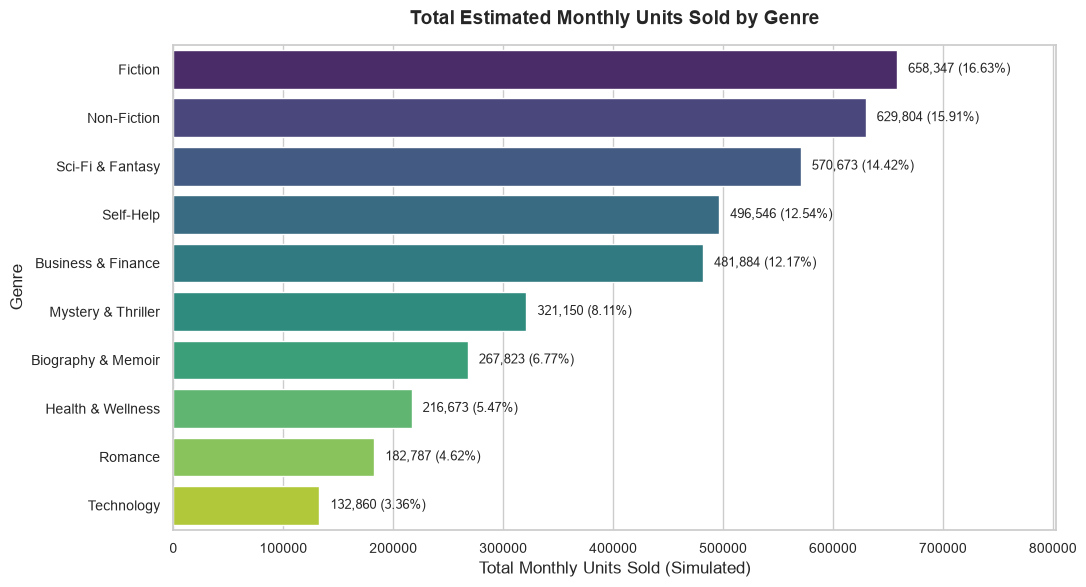

In [17]:
# Chart 2: Total Estimated Sales by Genre
plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=genre_analysis,
    x='total_monthly_sales',
    y='genre',
    hue='genre',
    legend=False,
    palette="viridis"
)
plt.title("Total Estimated Monthly Units Sold by Genre", weight='bold', pad=15)
plt.xlabel("Total Monthly Units Sold (Simulated)")
plt.ylabel("Genre")

for i, v in enumerate(genre_analysis['total_monthly_sales']):
    ax.text(v + 10000, i, f"{v:,} ({genre_analysis['sales_share_pct'].iloc[i]}%)", va='center', fontsize=9)

plt.xlim(0, max(genre_analysis['total_monthly_sales']) * 1.22)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "genre_sales.png", dpi=300)
plt.show()


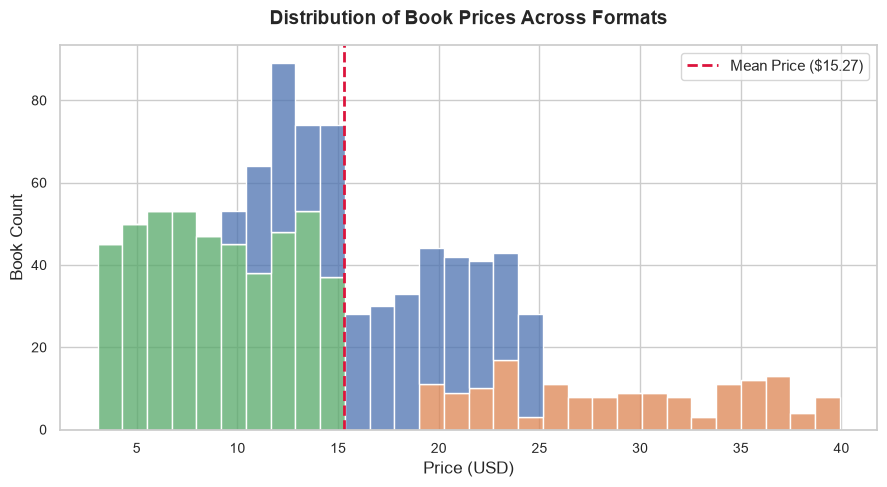

In [18]:
# Chart 3: Distribution of Book Prices Across Formats
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_clean,
    x='price_usd',
    hue='format',
    multiple='stack',
    bins=30,
    palette="deep",
    edgecolor="white"
)
plt.axvline(avg_price, color='crimson', linestyle='--', linewidth=2, label=f'Mean Price (${avg_price:.2f})')
plt.title("Distribution of Book Prices Across Formats", weight='bold', pad=15)
plt.xlabel("Price (USD)")
plt.ylabel("Book Count")
plt.legend()
plt.tight_layout()
plt.savefig(CHARTS_DIR / "price_distribution.png", dpi=300)
plt.show()


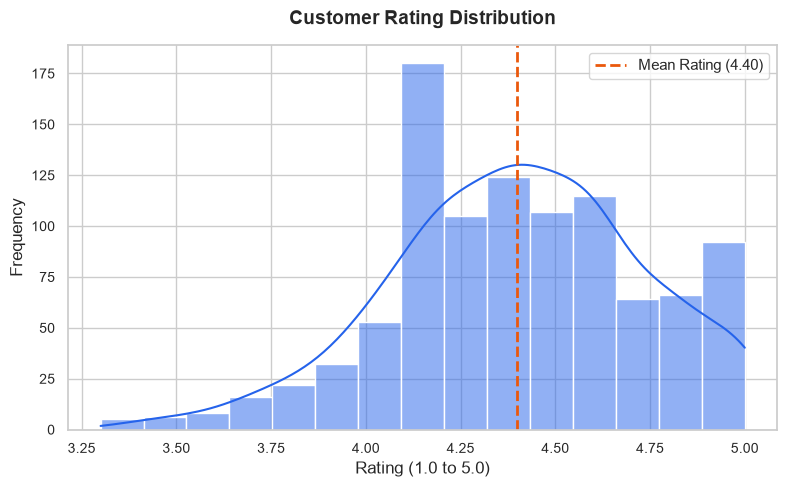

In [19]:
# Chart 4: Rating Distribution
plt.figure(figsize=(8, 5))
sns.histplot(
    df_clean['rating'],
    bins=15,
    kde=True,
    color="#2563eb",
    edgecolor="white"
)
plt.axvline(avg_rating, color='#ea580c', linestyle='--', linewidth=2, label=f'Mean Rating ({avg_rating:.2f})')
plt.title("Customer Rating Distribution", weight='bold', pad=15)
plt.xlabel("Rating (1.0 to 5.0)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.savefig(CHARTS_DIR / "rating_distribution.png", dpi=300)
plt.show()


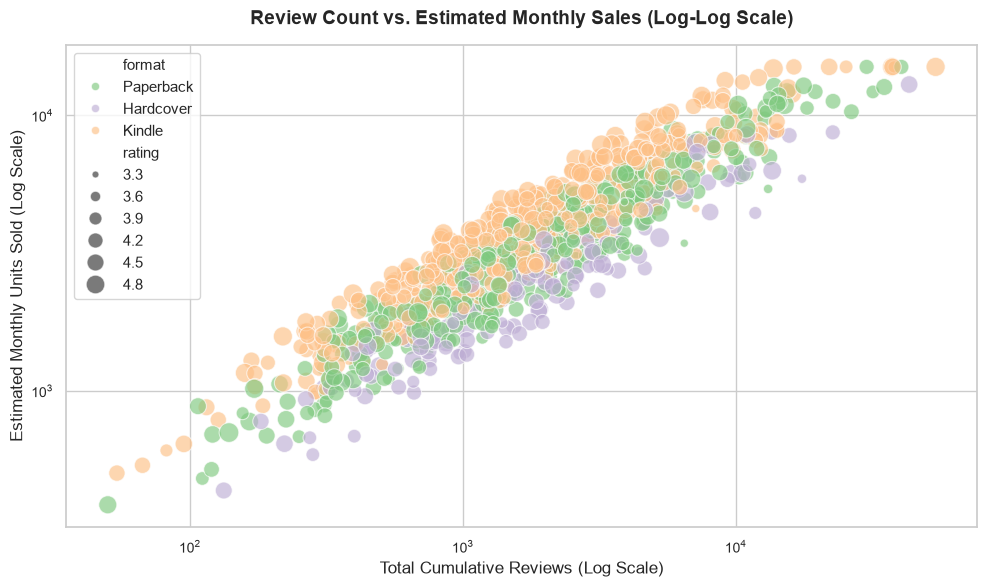

In [20]:
# Chart 5: Review Count vs. Estimated Monthly Sales
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x='review_count',
    y='estimated_monthly_units_sold',
    hue='format',
    size='rating',
    sizes=(25, 200),
    alpha=0.65,
    palette="Accent"
)
plt.xscale('log')
plt.yscale('log')
plt.title("Review Count vs. Estimated Monthly Sales (Log-Log Scale)", weight='bold', pad=15)
plt.xlabel("Total Cumulative Reviews (Log Scale)")
plt.ylabel("Estimated Monthly Units Sold (Log Scale)")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "reviews_vs_sales.png", dpi=300)
plt.show()


---
## 5. Business Insights & Strategic Findings

### 5.1 Evidence-Based Business Insights (Calculated Directly from Dataset)
1. **Fiction & Non-Fiction Drive Core Catalog Volume (32.54% Share):**  
   Fiction leads all genres with **658,347 units sold monthly** (16.63% market share across 164 titles), followed closely by Non-Fiction with **629,804 units** (15.91% share across 158 titles). Combined, these two categories represent **32.54%** of total catalog sales.
2. **Sci-Fi & Fantasy and Health & Wellness Boast Highest Sales Velocity:**  
   While Fiction has the highest gross volume due to catalog size, **Sci-Fi & Fantasy** achieves the highest average velocity per book at **4,258.8 units/title**, closely followed by **Health & Wellness** with **4,248.5 units/title**.
3. **Kindle Format Drives 53.25% of All Unit Sales:**  
   Digital Kindle editions account for **2,107,969 units** (53.25% of total sales volume) at an accessible average price of **$9.02**, outperforming Paperbacks (35.45% share, avg price $17.47) and Hardcovers (11.30% share, avg price $29.03).
4. **Strong Positive Correlation Between Reviews and Estimated Sales ($r = 0.811$):**  
   Cumulative reviews show a robust correlation of **0.811** with monthly unit sales, whereas customer ratings exhibit an almost neutral correlation with volume ($r = 0.098$). This indicates social proof and visibility matter more for ongoing sales volume than a marginal 0.1 difference in customer rating.
5. **High-Rated Powerhouse Books:**  
   There are **173 books** in the dataset that maintain both an exceptional rating ($\ge 4.5$) and over **5,000 reviews**. These titles serve as recurring bestsellers that yield disproportionate revenue and anchor brand credibility.

---

### 5.2 Critical Limitations of Interpreting Reviews as Direct Measures of Sales
When performing real-world e-commerce analytics, interpreting review count directly as sales volume has major limitations:
- **Lifetime Cumulative vs. Current Velocity:** Reviews accumulate over a book's entire lifespan (sometimes 10+ years), whereas monthly sales reflect current demand velocity. An older classic may have 60,000 reviews but sell only 200 copies a month today.
- **Review Submission Propensity Varies by Category & Audience:** Certain genres (e.g. self-help, technical books, controversial non-fiction) prompt significantly higher reader engagement than lightweight beach reads.
- **Format Discrepancies:** Kindle readers can leave a review with a single tap at the final page prompt, leading to a higher review conversion rate than physical paperback/hardcover buyers.
- **Promotional & Marketing Spikes:** Free book promotions, BookBub blasts, and Kindle Unlimited borrow cycles inflate review counts without reflecting sustained commercial unit sales.
